# Experimento binario: solo imágenes con CNN

Primer baseline de aprendizaje profundo para clasificar morfología MaNGA usando únicamente los cutouts RGB: `temprana = 0.0` y `tardia = 1.0`.

La cohorte y los splits persistidos permanecen fijos. La arquitectura es una CNN compacta entrenada desde cero y produce un único logit por galaxia.

In [32]:
from __future__ import annotations

import copy
import json
import random
import sys
import time
from pathlib import Path
from typing import Any, Mapping

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, balanced_accuracy_score, f1_score
from torch import nn
from tqdm.auto import tqdm


def project_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se encontró la raíz del proyecto.")


ROOT = project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataloader.multimodal import build_dataloaders
from src.evaluate import evaluate_binary_classifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Proyecto: {ROOT}")
print(f"Dispositivo: {DEVICE}")

Proyecto: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias
Dispositivo: cuda


## Configuración e invariantes

- El split `data/processed/splits_seed42_obj-label.csv` es fijo: no se regenera dentro de un experimento.
- Comparaciones de modalidades o arquitecturas mantienen la misma semilla, cohorte y protocolo de selección.
- La selección de checkpoints usa solo validación; `test` se consulta una única vez para el modelo seleccionado.
- Se usa una salida logit por galaxia y `BCEWithLogitsLoss`.

In [33]:
CONFIG: dict[str, Any] = {
    "experiment_name": "experimento_binario_imagenes_cnn_gpu_gamma",
    "seed": 42,
    "data": {
        "project_root": ROOT,
        "manifest": "data/galaxy_manifest.csv",
        "splits": "data/processed/splits_seed42_obj-label.csv",
        "modalities": ["image"],
        "image": {
            "fov_column": "fov_0",
            "size": 256,
            "normalization": "none",
        },
    },
    "training": {
        "batch_size": 32,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
        "epochs": 50,
        "learning_rate": 3e-4,
        "weight_decay": 1e-4,
        "max_grad_norm": 1.0,
        "early_stopping_patience": 8,
    },
    "selection_metric": "roc_auc",
}

RUN_DIR = ROOT / "models" / "experiments" / CONFIG["experiment_name"]
CHECKPOINT_PATH = RUN_DIR / "best_model.pt"
RESULTS_PATH = RUN_DIR / "results.json"
CONFIG_PATH = RUN_DIR / "config.json"

In [34]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["seed"])
train_loader, validation_loader, test_loader = build_dataloaders(CONFIG)
loaders = {"train": train_loader, "validation": validation_loader, "test": test_loader}

for split_name, loader in loaders.items():
    labels = loader.dataset.frame["label"].value_counts()
    print(f"{split_name:10s} n={len(loader.dataset):5d}  temprana={labels.get('temprana', 0):5d}  tardia={labels.get('tardia', 0):5d}")

sample_batch = next(iter(train_loader))
for key, value in sample_batch.items():
    if isinstance(value, torch.Tensor):
        print(f"{key:16s} {tuple(value.shape)} {value.dtype}")
    else:
        print(f"{key:16s} {type(value).__name__}")

train      n= 6545  temprana= 2467  tardia= 4078
validation n= 1403  temprana=  529  tardia=  874
test       n= 1403  temprana=  528  tardia=  875
id               list
label            (32,) torch.float32
image            (32, 3, 256, 256) torch.float32


## Arquitectura: CNN solo imágenes

La red usa cuatro bloques `Conv2d -> BatchNorm2d -> ReLU -> MaxPool2d` con 32, 64, 128 y 256 canales. Cada bloque contiene dos convoluciones; al final, `AdaptiveAvgPool2d` y `Dropout -> Linear(256, 1)` producen un logit binario.

Es una línea base adecuada: aprende rasgos espaciales sin pesos externos, tiene capacidad moderada para los cutouts de $256 \times 256$ y permite verificar el pipeline antes de explorar transfer learning.

In [35]:
class ImageOnlyCNN(nn.Module):
    def __init__(self, dropout: float = 0.30) -> None:
        super().__init__()

        def conv_block(in_channels: int, out_channels: int) -> nn.Sequential:
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=2),
            )

        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, 1),
        )

    def forward(self, batch: Mapping[str, torch.Tensor]) -> torch.Tensor:
        return self.classifier(self.features(batch["image"])).squeeze(1)


def build_model(config: Mapping[str, Any], batch: Mapping[str, Any]) -> nn.Module:
    if "image" not in batch:
        raise ValueError("Este experimento requiere batch['image'].")
    return ImageOnlyCNN()


model = build_model(CONFIG, sample_batch).to(DEVICE)
with torch.no_grad():
    smoke_logits = model({"image": sample_batch["image"].to(DEVICE)})
assert smoke_logits.shape == sample_batch["label"].shape

parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model)
print(f"Parámetros entrenables: {parameter_count:,}")
print(f"Logits de smoke test: {tuple(smoke_logits.shape)}")

ImageOnlyCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(i

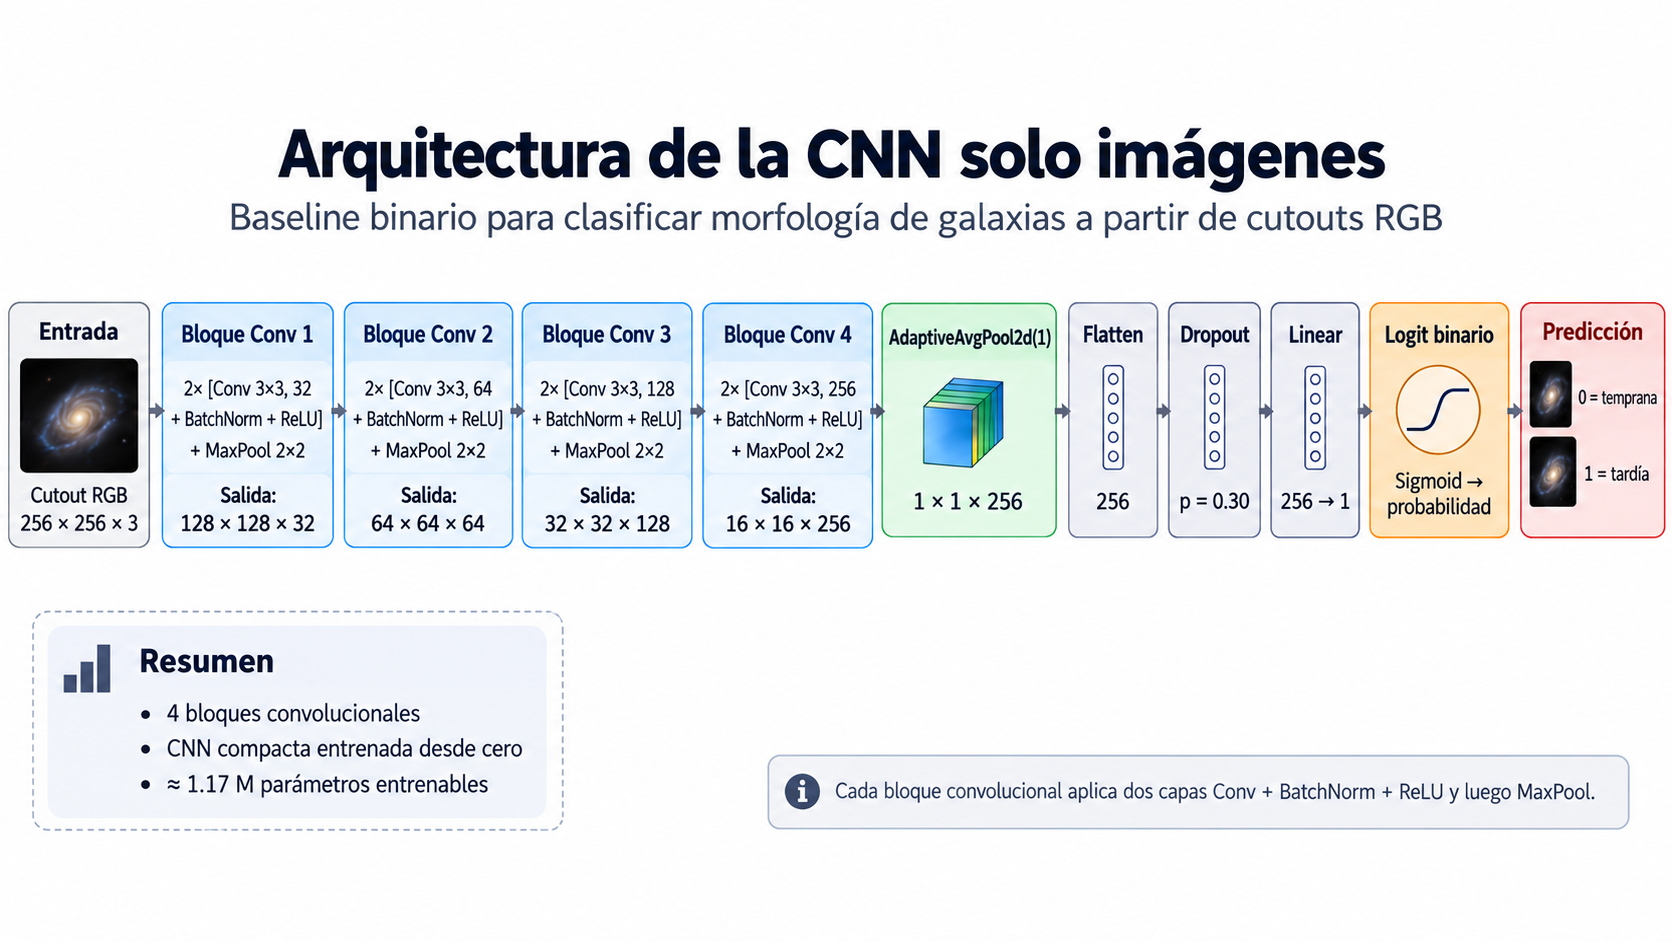

In [36]:
def move_batch_to_device(batch: Mapping[str, Any], device: torch.device) -> dict[str, Any]:
    return {
        key: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
        for key, value in batch.items()
    }


def logits_from_model(model: nn.Module, batch: Mapping[str, Any]) -> torch.Tensor:
    logits = model(batch)
    expected_shape = batch["label"].shape
    if logits.shape != expected_shape:
        raise ValueError(f"El modelo devolvió {tuple(logits.shape)}; se esperaba {tuple(expected_shape)}.")
    if not torch.isfinite(logits).all():
        raise FloatingPointError("El modelo produjo logits no finitos.")
    return logits


def train_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    epoch: int,
    total_epochs: int,
    max_grad_norm: float,
) -> float:
    model.train()
    total_loss = 0.0
    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d}/{total_epochs}",
        unit="batch",
        leave=False,
    )
    for batch in progress:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(logits_from_model(model, batch), batch["label"])
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida de entrenamiento dejó de ser finita.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        optimizer.step()
        total_loss += loss.item() * batch["label"].numel()
        progress.set_postfix(train_loss=f"{total_loss / len(loader.dataset):.4f}")
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_true, all_pred, all_proba = [], [], []
    for batch in loader:
        # Preserve labels on CPU: MPS integer transfers can corrupt metric targets.
        labels_cpu = batch["label"].to(torch.int64).numpy().copy()
        batch = move_batch_to_device(batch, device)
        logits = logits_from_model(model, batch)
        loss = criterion(logits, batch["label"])
        if not torch.isfinite(loss):
            raise FloatingPointError("La pérdida de validación dejó de ser finita.")
        total_loss += loss.item() * batch["label"].numel()
        probabilities_cpu = torch.sigmoid(logits).detach().cpu().numpy().copy()
        all_true.append(labels_cpu)
        all_pred.append((probabilities_cpu >= 0.5).astype(np.int64, copy=False))
        all_proba.append(probabilities_cpu.astype(np.float64, copy=False))

    y_true = np.concatenate(all_true).astype(np.int64, copy=False).reshape(-1)
    y_pred = np.concatenate(all_pred).astype(np.int64, copy=False).reshape(-1)
    y_proba = np.concatenate(all_proba).astype(np.float64, copy=False).reshape(-1)
    observed_labels = np.unique(y_true)
    if not np.isin(y_true, [0, 1]).all():
        raise ValueError(
            "Las etiquetas de evaluación deben pertenecer a {0, 1}. "
            f"Valores observados: {observed_labels.tolist()}."
        )
    if observed_labels.size != 2:
        raise ValueError(
            "Validación debe contener ambas clases para calcular ROC-AUC. "
            f"Valores observados: {observed_labels.tolist()}."
        )
    return total_loss / len(loader.dataset), y_true, y_pred, y_proba

In [37]:
def fit(
    model: nn.Module,
    train_loader: torch.utils.data.DataLoader,
    validation_loader: torch.utils.data.DataLoader,
    config: Mapping[str, Any],
    device: torch.device,
    checkpoint_path: Path,
) -> pd.DataFrame:
    training_config = config["training"]
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=training_config["learning_rate"],
        weight_decay=training_config["weight_decay"],
    )
    history: list[dict[str, float]] = []
    best_score = float("-inf")
    best_state: dict[str, torch.Tensor] | None = None
    epochs_without_improvement = 0

    for epoch in range(1, training_config["epochs"] + 1):
        started_at = time.perf_counter()
        train_loss = train_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device,
            epoch,
            training_config["epochs"],
            training_config["max_grad_norm"],
        )
        validation_loss, y_true, y_pred, y_proba = evaluate_epoch(
            model, validation_loader, criterion, device
        )
        metrics = evaluate_binary_classifier(y_true, y_pred, y_proba)
        score = float(metrics[config["selection_metric"]])
        if not np.isfinite(score):
            raise FloatingPointError("La métrica de selección no es finita.")
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": float(metrics["accuracy"]),
                "validation_balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "validation_f1": f1_score(y_true, y_pred, zero_division=0),
                "validation_roc_auc": float(metrics["roc_auc"]),
                "seconds": time.perf_counter() - started_at,
            }
        )
        print(
            f"[{epoch:02d}/{training_config['epochs']}] "
            f"train_loss={train_loss:.4f} val_loss={validation_loss:.4f} "
            f"val_auc={metrics['roc_auc']:.4f}"
        )

        if score > best_score:
            best_score = score
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= training_config["early_stopping_patience"]:
                print("Early stopping por validación.")
                break

    if best_state is None:
        raise RuntimeError("No se obtuvo un checkpoint de validación.")
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "config": dict(config)}, checkpoint_path)
    return pd.DataFrame(history)


# Ejecutar esta celda inicia el entrenamiento y selecciona el mejor checkpoint por ROC-AUC de validación.
history = fit(model, train_loader, validation_loader, CONFIG, DEVICE, CHECKPOINT_PATH)
history.tail()

[01/50] train_loss=0.4323 val_loss=0.4304 val_auc=0.8982


[02/50] train_loss=0.3925 val_loss=0.3798 val_auc=0.9130


[03/50] train_loss=0.3661 val_loss=0.5669 val_auc=0.8996


[04/50] train_loss=0.3598 val_loss=0.3981 val_auc=0.9172


[05/50] train_loss=0.3446 val_loss=0.5046 val_auc=0.9091


[06/50] train_loss=0.3296 val_loss=0.3777 val_auc=0.9323


... (31 outputs left out)

[38/50] train_loss=0.2483 val_loss=0.2617 val_auc=0.9580


[39/50] train_loss=0.2415 val_loss=0.2629 val_auc=0.9565


[40/50] train_loss=0.2457 val_loss=0.2864 val_auc=0.9540
Early stopping por validación.


,epoch,train_loss,validation_loss,validation_accuracy,validation_balanced_accuracy,validation_f1,validation_roc_auc,seconds
35,36,0.250458,0.299794,0.878118,0.891354,0.895413,0.956550,27.175565
36,37,0.254278,0.283310,0.893799,0.885658,0.915100,0.950930,26.998326
37,38,0.248287,0.261708,0.885959,0.889066,0.905437,0.958001,27.019727
38,39,0.241498,0.262891,0.888810,0.881654,0.910755,0.956461,27.019050
39,40,0.245713,0.286394,0.883108,0.860661,0.910284,0.953974,27.118403


## Evaluación final y persistencia

Ejecute esta sección solo después de decidir la arquitectura e hiperparámetros usando validación. El split de `test` no participa en selección, calibración ni early stopping.

test_loss=0.2550  test_accuracy=0.8874  test_auc=0.9627
              precision    recall  f1-score      support
0              0.808333  0.918561  0.859929   528.000000
1              0.946451  0.868571  0.905840   875.000000
accuracy       0.887384  0.887384  0.887384     0.887384
macro avg      0.877392  0.893566  0.882885  1403.000000
weighted avg   0.894472  0.887384  0.888562  1403.000000


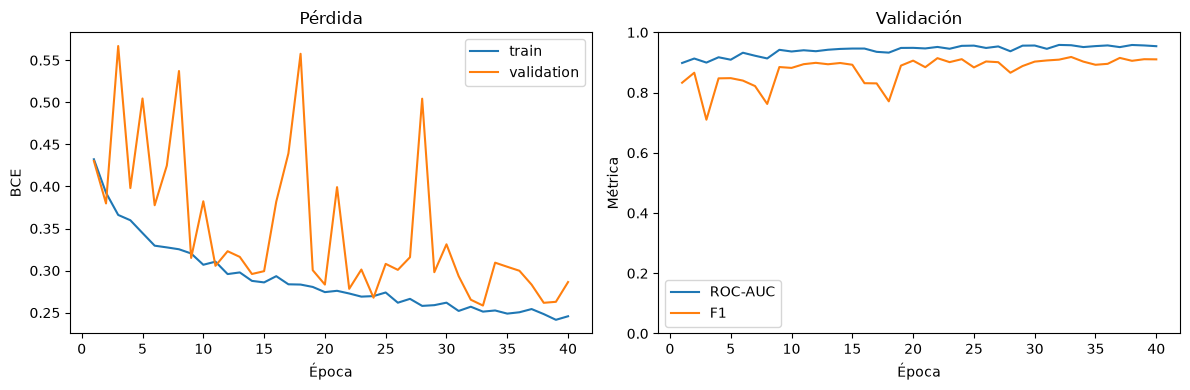

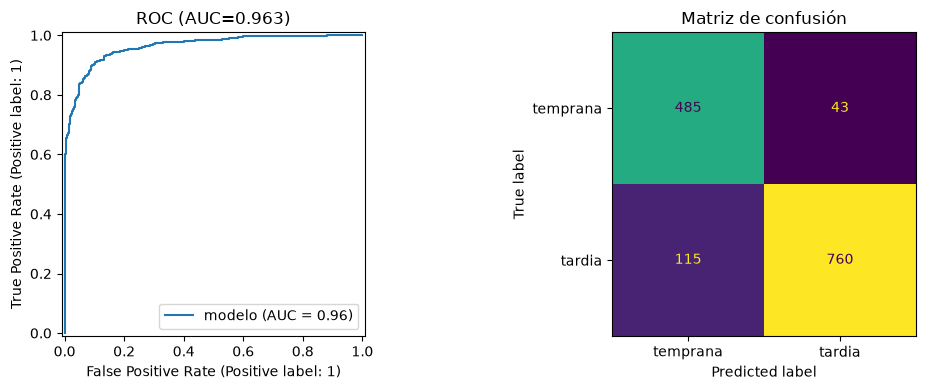

In [38]:
def plot_history(history: pd.DataFrame) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["validation_loss"], label="validation")
    axes[0].set(title="Pérdida", xlabel="Época", ylabel="BCE")
    axes[0].legend()
    axes[1].plot(history["epoch"], history["validation_roc_auc"], label="ROC-AUC")
    axes[1].plot(history["epoch"], history["validation_f1"], label="F1")
    axes[1].set(title="Validación", xlabel="Época", ylabel="Métrica", ylim=(0, 1))
    axes[1].legend()
    figure.tight_layout()


def plot_binary_evaluation(y_true: np.ndarray, y_proba: np.ndarray, metrics: Mapping[str, Any]) -> None:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y_true, y_proba, ax=axes[0], name="modelo")
    axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=["temprana", "tardia"],
    ).plot(ax=axes[1], colorbar=False)
    axes[1].set_title("Matriz de confusión")
    figure.tight_layout()


def to_jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Mapping):
        return {str(key): to_jsonable(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(item) for item in value]
    return value


def save_run_artifacts(
    config: Mapping[str, Any], history: pd.DataFrame, test_metrics: Mapping[str, Any]
) -> None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    with CONFIG_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(config), file, indent=2)
    history.to_csv(RUN_DIR / "history.csv", index=False)
    with RESULTS_PATH.open("w", encoding="utf-8") as file:
        json.dump(to_jsonable(test_metrics), file, indent=2)


# Después de seleccionar el experimento con validación:
criterion = nn.BCEWithLogitsLoss()
test_loss, y_test, y_test_pred, y_test_proba = evaluate_epoch(model, test_loader, criterion, DEVICE)
test_metrics = evaluate_binary_classifier(y_test, y_test_pred, y_test_proba)
print(f"test_loss={test_loss:.4f}  test_accuracy={test_metrics['accuracy']:.4f}  test_auc={test_metrics['roc_auc']:.4f}")
print(pd.DataFrame(test_metrics["report"]).T)
plot_history(history)
plot_binary_evaluation(y_test, y_test_proba, test_metrics)
save_run_artifacts(CONFIG, history, {"test_loss": test_loss, **test_metrics})

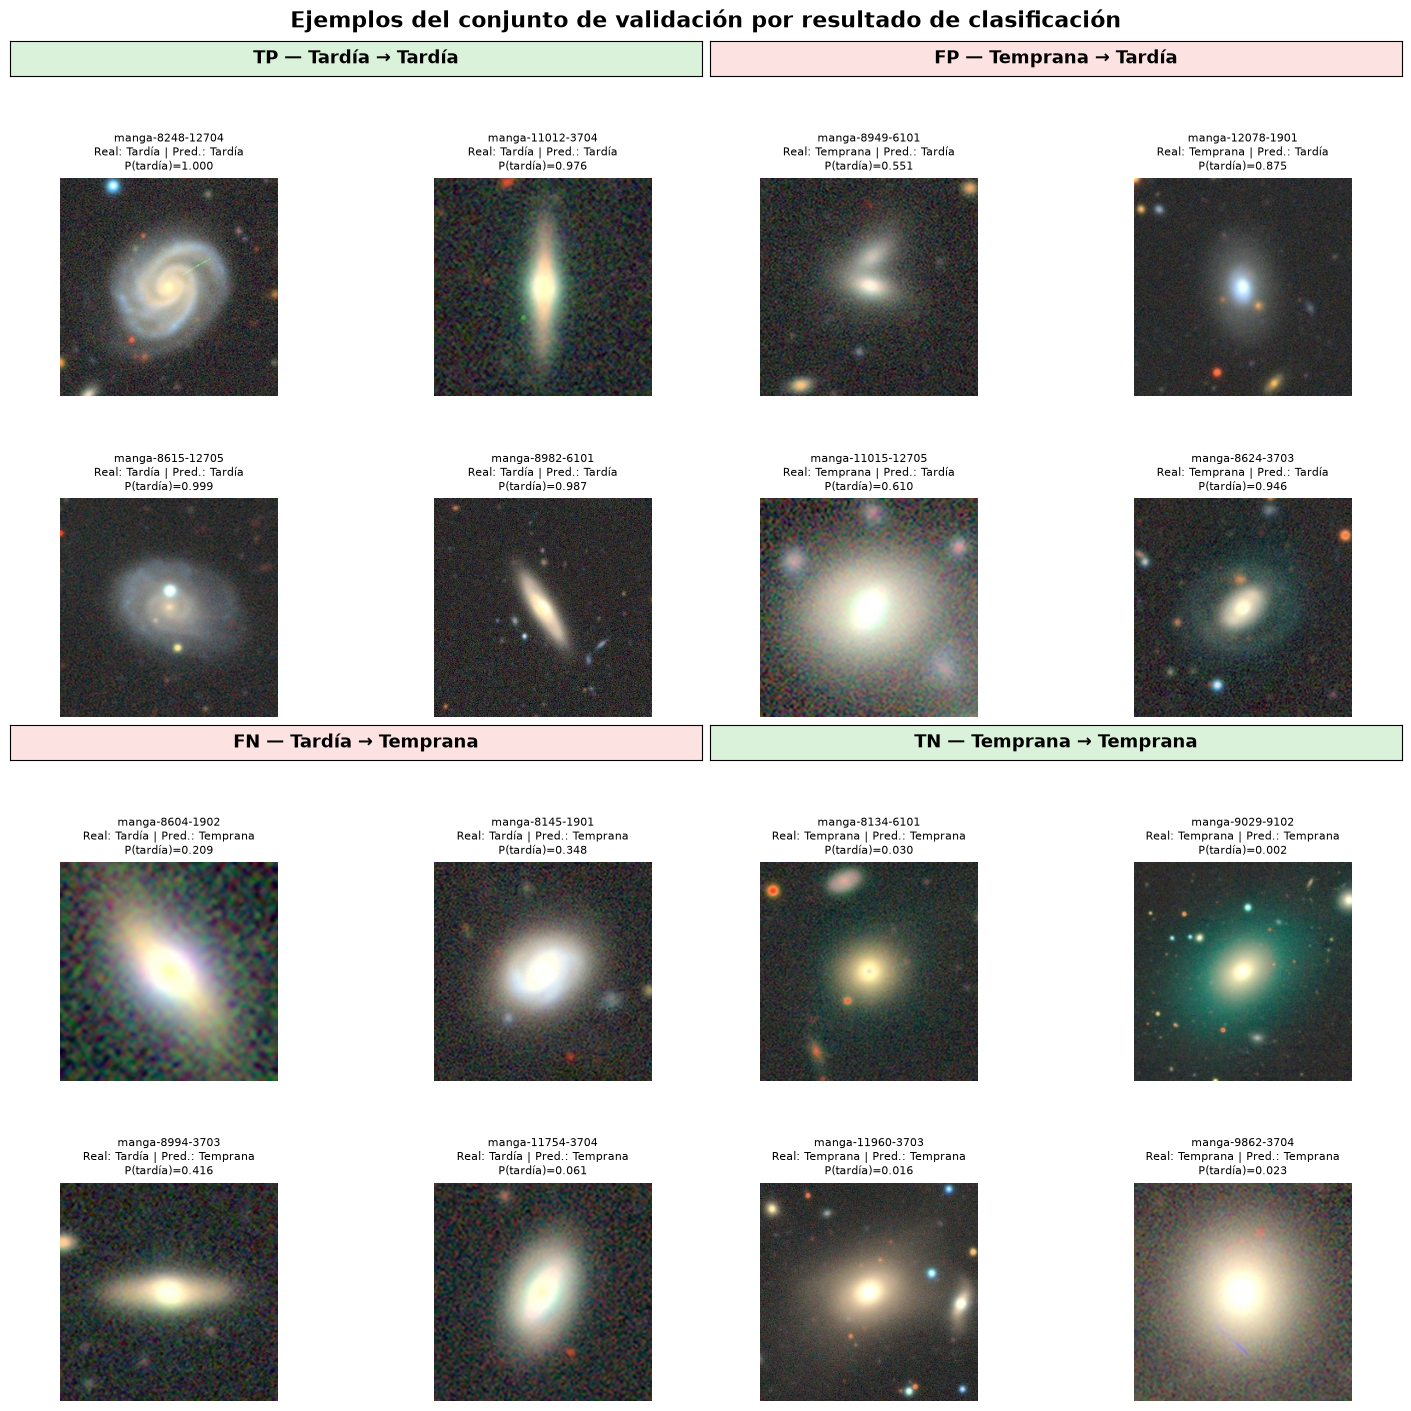

In [39]:
# Evaluación visual del modelo:
# matriz de confusión + 4 ejemplos TN, TP, FP y FN del split de validación.
#
# Convención del proyecto:
#   0 = temprana
#   1 = tardía
#
# Por tanto:
#   TN: temprana -> temprana
#   TP: tardía   -> tardía
#   FP: temprana -> tardía
#   FN: tardía   -> temprana

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix

CLASS_NAMES = {0: "Temprana", 1: "Tardía"}
THRESHOLD = 0.5
N_EXAMPLES_PER_GROUP = 4
RNG = np.random.default_rng(42)

model.eval()

all_ids = []
all_images = []
all_targets = []
all_probabilities = []

with torch.no_grad():
    for batch in validation_loader:
        batch_on_device = {
            key: value.to(DEVICE, non_blocking=True)
            if isinstance(value, torch.Tensor)
            else value
            for key, value in batch.items()
        }

        logits = model(batch_on_device).squeeze(-1)
        probabilities = torch.sigmoid(logits)

        all_ids.extend(batch["id"])
        all_images.append(batch["image"].cpu())
        all_targets.append(batch["label"].to(torch.int64).cpu())
        all_probabilities.append(probabilities.cpu())

images = torch.cat(all_images).numpy()
y_true = torch.cat(all_targets).numpy()
y_proba = torch.cat(all_probabilities).numpy()
y_pred = (y_proba >= THRESHOLD).astype(np.int64)

# --- Matriz de confusión ---
matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

# --- Índices por resultado de clasificación ---
groups = {
    "TN — Temprana → Temprana": np.flatnonzero(
        (y_true == 0) & (y_pred == 0)
    ),
    "TP — Tardía → Tardía": np.flatnonzero(
        (y_true == 1) & (y_pred == 1)
    ),
    "FP — Temprana → Tardía": np.flatnonzero(
        (y_true == 0) & (y_pred == 1)
    ),
    "FN — Tardía → Temprana": np.flatnonzero(
        (y_true == 1) & (y_pred == 0)
    ),
}

# Revertir la normalización ImageNet aplicada por el transform de imágenes.
def image_for_display_imagenet(image: np.ndarray) -> np.ndarray:
    image = np.moveaxis(image, 0, -1)  # C, H, W -> H, W, C

    imagenet_mean = np.array([0.485, 0.456, 0.406])
    imagenet_std = np.array([0.229, 0.224, 0.225])

    image = image * imagenet_std + imagenet_mean
    return np.clip(image, 0, 1)

def image_for_display(image: np.ndarray) -> np.ndarray:
    """Convierte una imagen CxHxW en HxWxC para matplotlib."""
    image = np.moveaxis(image, 0, -1)  # C, H, W -> H, W, C
    return np.clip(image, 0, 1)


# --- Panel por cuadrantes: cuatro ejemplos en cada categoría ---
#
# Organización visual solicitada:
#     TP | FP
#    ---+---
#     FN | TN

quadrants = [
    (
        "TP — Tardía → Tardía",
        np.flatnonzero((y_true == 1) & (y_pred == 1)),
        "#d9f2d9",
    ),
    (
        "FP — Temprana → Tardía",
        np.flatnonzero((y_true == 0) & (y_pred == 1)),
        "#fde2e2",
    ),
    (
        "FN — Tardía → Temprana",
        np.flatnonzero((y_true == 1) & (y_pred == 0)),
        "#fde2e2",
    ),
    (
        "TN — Temprana → Temprana",
        np.flatnonzero((y_true == 0) & (y_pred == 0)),
        "#d9f2d9",
    ),
]

fig = plt.figure(figsize=(14, 14), constrained_layout=True)
outer_grid = fig.add_gridspec(nrows=2, ncols=2, wspace=0.08, hspace=0.12)

for quadrant_index, (title, indices, background_color) in enumerate(quadrants):
    row, column = divmod(quadrant_index, 2)
    quadrant_grid = outer_grid[row, column].subgridspec(
        nrows=3,
        ncols=2,
        height_ratios=[0.16, 1, 1],
        hspace=0.12,
        wspace=0.08,
    )

    # Título que ocupa el ancho completo del cuadrante.
    title_ax = fig.add_subplot(quadrant_grid[0, :])
    title_ax.set_facecolor(background_color)
    title_ax.text(
        0.5,
        0.5,
        title,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold",
    )
    title_ax.set_xticks([])
    title_ax.set_yticks([])

    if len(indices) == 0:
        selected_indices = np.array([], dtype=int)
        print(f"No hay ejemplos para: {title}")
    else:
        selected_indices = RNG.choice(
            indices,
            size=min(N_EXAMPLES_PER_GROUP, len(indices)),
            replace=False,
        )

    # Cuadrícula interior 2x2: cuatro ejemplos del tipo indicado.
    for example_position in range(N_EXAMPLES_PER_GROUP):
        image_row, image_column = divmod(example_position, 2)
        ax = fig.add_subplot(
            quadrant_grid[image_row + 1, image_column]
        )

        if example_position >= len(selected_indices):
            ax.axis("off")
            continue

        index = selected_indices[example_position]

        ax.imshow(image_for_display(images[index]))
        ax.set_title(
            f"{all_ids[index]}\n"
            f"Real: {CLASS_NAMES[y_true[index]]} | "
            f"Pred.: {CLASS_NAMES[y_pred[index]]}\n"
            f"P(tardía)={y_proba[index]:.3f}",
            fontsize=8,
        )
        ax.axis("off")

fig.suptitle(
    "Ejemplos del conjunto de validación por resultado de clasificación",
    fontsize=16,
    fontweight="bold",
)
plt.show()

In [40]:
# Guarda
RUN_DIR.mkdir(parents=True, exist_ok=True)

experiment_data = {
    "model_state_dict": {
        name: tensor.detach().cpu()
        for name, tensor in model.state_dict().items()
    },
    "config": to_jsonable(CONFIG),
    "device": str(DEVICE),
    "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
    "history": history.to_dict(orient="records"),
    "test_metrics": to_jsonable(
        {"test_loss": test_loss, **test_metrics}
    ),
}

checkpoint_path = RUN_DIR / "experiment_checkpoint.pt"
torch.save(experiment_data, checkpoint_path)

with (RUN_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(to_jsonable(CONFIG), file, indent=2)

history.to_csv(RUN_DIR / "history.csv", index=False)

with (RUN_DIR / "test_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(
        to_jsonable({"test_loss": test_loss, **test_metrics}),
        file,
        indent=2,
    )

print(f"Modelo y resultados guardados en: {RUN_DIR}")
print(f"Checkpoint: {checkpoint_path}")

Modelo y resultados guardados en: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/experimento_binario_imagenes_cnn_gpu_gamma
Checkpoint: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/experimento_binario_imagenes_cnn_gpu_gamma/experiment_checkpoint.pt


# Save predictions for analysis

In [41]:
from torch.utils.data import DataLoader

# Cargar el mejor checkpoint
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE).eval()

THRESHOLD = 0.5
INT_TO_LABEL = {0: "temprana", 1: "tardia"}


@torch.no_grad()
def predict_split(dataset, split_name: str) -> pd.DataFrame:
    # El loader de train usa shuffle=True; se reconstruye sin shuffle para predecir.
    loader = DataLoader(
        dataset,
        batch_size=CONFIG["training"]["batch_size"],
        shuffle=False,
        num_workers=CONFIG["training"]["num_workers"],
        pin_memory=CONFIG["training"]["pin_memory"],
    )
    rows = []
    for batch in tqdm(loader, desc=f"Predict {split_name}", unit="batch", leave=False):
        ids = list(batch["id"])
        labels = batch["label"].to(torch.int64).numpy()
        logits = model(move_batch_to_device(batch, DEVICE))
        probas = torch.sigmoid(logits).cpu().numpy().astype(np.float64)
        rows.append(
            pd.DataFrame(
                {
                    "name": ids,
                    "split": split_name,
                    "y_true": labels,
                    "y_proba": probas,
                    "y_pred": (probas >= THRESHOLD).astype(np.int64),
                }
            )
        )
    return pd.concat(rows, ignore_index=True)


predictions = pd.concat(
    [
        predict_split(loader.dataset, split_name)
        for split_name, loader in loaders.items()
    ],
    ignore_index=True,
)
predictions["label"] = predictions["y_true"].map(INT_TO_LABEL)
predictions["pred_label"] = predictions["y_pred"].map(INT_TO_LABEL)
predictions["correct"] = predictions["y_true"] == predictions["y_pred"]
predictions = predictions[
    ["name", "split", "label", "y_true", "y_proba", "y_pred", "pred_label", "correct"]
]

PREDICTIONS_PATH = RUN_DIR / "predictions.csv"
predictions.to_csv(PREDICTIONS_PATH, index=False)
print(f"Guardado: {PREDICTIONS_PATH}  ({len(predictions)} filas)")
print(predictions.groupby("split")["correct"].mean().rename("accuracy"))
predictions.head()

Guardado: /home/albertor/Documents/deep_learning/repos/clasificacion-galaxias/models/experiments/experimento_binario_imagenes_cnn_gpu_gamma/predictions.csv  (9351 filas)
split
test          0.887384
train         0.894882
validation    0.890235
Name: accuracy, dtype: float64


,name,split,label,y_true,y_proba,y_pred,pred_label,correct
0,manga-10001-12701,train,tardia,1,0.997332,1,tardia,True
1,manga-10001-1902,train,temprana,0,0.295560,0,temprana,True
2,manga-10001-3702,train,temprana,0,0.127104,0,temprana,True
3,manga-10001-3703,train,tardia,1,0.961195,1,tardia,True
4,manga-10001-3704,train,temprana,0,0.025706,0,temprana,True
